In [36]:
import tensorflow
from tensorflow.keras.applications import VGG19
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.models import Sequential
from tensorflow.keras.datasets import mnist
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [22]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train, y_train = X_train[:5000], y_train[:5000]
X_test, y_test = X_test[:1000], y_test[1000:]

In [23]:
def preprocess_images(images):
    images_resized = np.array([cv2.resize(img, (32,32)) for img in images])
    images_rgb = np.stack((images_resized,)*3, axis=-1)
    return images_rgb.astype('float32') / 255.0

In [24]:
X_train, X_test = preprocess_images(X_train), preprocess_images(X_test)

In [26]:
base_model = VGG19(weights='imagenet', include_top=False, input_shape=(32,32,3))
for layer in base_model.layers:
    layer.trainable = False

In [27]:
model = Sequential([
    base_model,
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

In [30]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [32]:
history = model.fit(X_train, y_train, epochs=5, validation_split=0.2, batch_size=64)

Epoch 1/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 225ms/step - accuracy: 0.8910 - loss: 0.4468 - val_accuracy: 0.8930 - val_loss: 0.4092
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 198ms/step - accuracy: 0.9125 - loss: 0.3466 - val_accuracy: 0.9140 - val_loss: 0.3478
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 196ms/step - accuracy: 0.9225 - loss: 0.2927 - val_accuracy: 0.9200 - val_loss: 0.3065
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 187ms/step - accuracy: 0.9305 - loss: 0.2524 - val_accuracy: 0.9250 - val_loss: 0.2740
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 191ms/step - accuracy: 0.9358 - loss: 0.2282 - val_accuracy: 0.9320 - val_loss: 0.2526


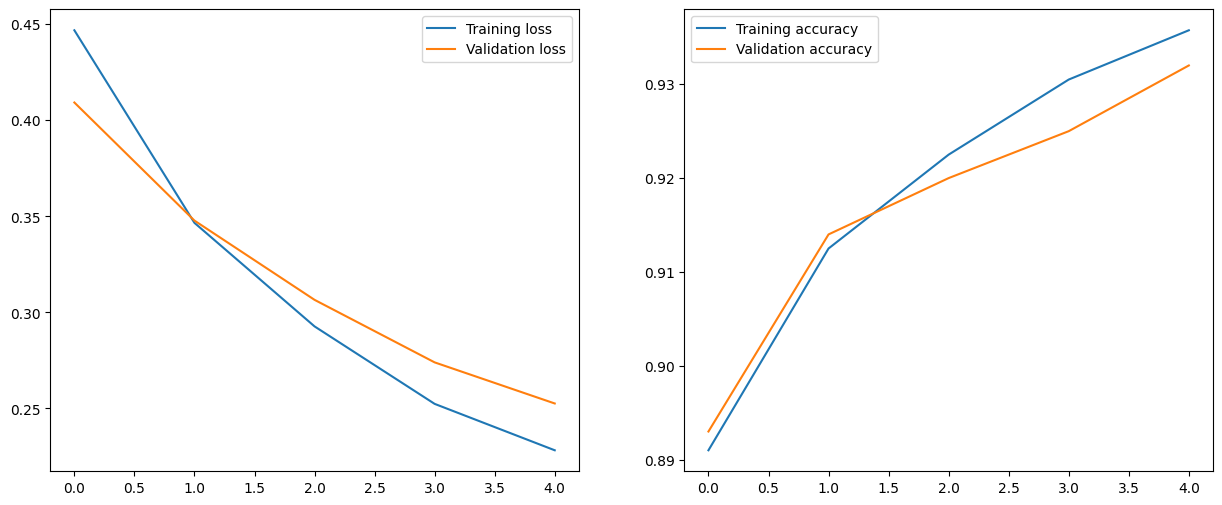

In [34]:
plt.figure(figsize=(15,6))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.legend()
plt.show()
